In [1]:
import os
import json
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets
import wandb

import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
os.chdir('/home/ubuntu/work/saved_data/Global-Canopy-Height-Map')

In [3]:
os.getcwd()

'/home/ubuntu/work/saved_data/Global-Canopy-Height-Map'

In [4]:
# Adjust model variant
MODEL_VARIANT = 'quantiles' #'baseline', 'ensemble', 'gaussian', 'quantiles'

PREDICTIONS_FILE = f"prediction_outputs/predictions_{MODEL_VARIANT}.json"
print(PREDICTIONS_FILE)

prediction_outputs/predictions_quantiles.json


In [5]:
def inspect_json_structure(predictions_file, num_entries=3):
    """
    Loads and prints an overview of the JSON file structure.
    
    :param predictions_file: Path to the JSON file containing predictions.
    :param num_entries: Number of entries to print for inspection.
    """
    with open(predictions_file, "r") as f:
        data = json.load(f)

    print(f"🔍 JSON contains {len(data)} prediction entries.\n")
    
    # Inspect general structure
    print("🗂 Available keys in first entry:")
    for key in data[0].keys():
        print(f"  - {key}")

    # Inspect details inside an entry
    print("\n🔹 Example structure of first entry:")
    example_entry = data[0]
    for key, value in example_entry.items():
        if isinstance(value, dict):
            print(f"  {key}: (Dictionary with keys: {list(value.keys())})")
        elif isinstance(value, list):
            print(f"  {key}: (List of length {len(value)})")
        else:
            print(f"  {key}: {type(value)}")

    # Inspect available output keys
    print("\n🛠 Available output keys in 'outputs':")
    if "outputs" in example_entry:
        for output_key, output_value in example_entry["outputs"].items():
            print(f"  - {output_key}: {type(output_value)} | Shape: {np.shape(output_value)}")

    # Inspect individual ensemble members
    print("\n👥 Checking for ensemble member predictions...")
    if "ensemble_members" in example_entry["outputs"]:
        num_members = len(example_entry["outputs"]["ensemble_members"])
        print(f"  ✅ Found {num_members} ensemble member predictions.")
    else:
        print("  ❌ No ensemble member predictions found. Ensure they are saved correctly.")

    # Print a sample entry
    print("\n📌 Example entry preview:")
    print(json.dumps(example_entry, indent=2)[:1000])  # Print only the first 1000 characters for readability

# Run the inspection
inspect_json_structure(PREDICTIONS_FILE)


🔍 JSON contains 16 prediction entries.

🗂 Available keys in first entry:
  - file_name
  - input_image
  - variant
  - outputs

🔹 Example structure of first entry:
  file_name: <class 'str'>
  input_image: (List of length 14)
  variant: <class 'str'>
  outputs: (Dictionary with keys: ['q10', 'q25', 'q50', 'q75', 'q90'])

🛠 Available output keys in 'outputs':
  - q10: <class 'list'> | Shape: (2, 512, 512)
  - q25: <class 'list'> | Shape: (2, 512, 512)
  - q50: <class 'list'> | Shape: (2, 512, 512)
  - q75: <class 'list'> | Shape: (2, 512, 512)
  - q90: <class 'list'> | Shape: (2, 512, 512)

👥 Checking for ensemble member predictions...
  ❌ No ensemble member predictions found. Ensure they are saved correctly.

📌 Example entry preview:
{
  "file_name": "sentinel_1_2_worldwide_utm_33N_28-0000125440-0000000000_3",
  "input_image": [
    [
      [
        7386.0,
        7423.0,
        7601.0,
        7532.0,
        7104.0,
        7085.0,
        6881.0,
        6579.0,
        5993.0,
 

In [6]:
def stream_predictions(predictions_file):
    """
    Stream predictions one-by-one from the JSON file to avoid high memory usage.
    """
    with open(predictions_file, "r") as f:
        data = json.load(f)
        for entry in data:  # Process one entry at a time
            yield entry  # Return one image entry at a time

In [7]:
def visualize_prediction_interactive(entry, save_path="saved_visualizations", rgb_channels=[6, 5, 4]):
    """
    Interactive visualization with an option to save.
    
    :param entry: Prediction entry from the JSON file.
    :param save_path: Directory where visualizations will be saved.
    :param rgb_channels: Indices for RGB visualization.
    """
    file_name = entry["file_name"]
    x_input = torch.tensor(entry["input_image"])  # Convert input image back to tensor
    outputs = entry["outputs"]
    
    # Extract main ensemble predictions
    mean_prediction = torch.tensor(outputs["mean"])
    std_dev = torch.tensor(outputs["std_dev"]) if "std_dev" in outputs else None
    lower_bound = torch.tensor(outputs["lower_bound"]) if "lower_bound" in outputs else None
    upper_bound = torch.tensor(outputs["upper_bound"]) if "upper_bound" in outputs else None
    
    # Extract individual ensemble members
    ensemble_members = outputs.get("individual_predictions", [])

    # Normalize input for visualization
    #inputs_min, inputs_max = np.percentile(x_input.numpy(), (2, 98))
    #x_input_normalized = (x_input.numpy() - inputs_min) / (inputs_max - inputs_min + 1e-6)
    #x_input_normalized = np.clip(x_input_normalized, 0, 1)
    x_input_normalized = np.clip(x_input.numpy() / 3000, 0, 1)

    # Ensure correct dimensions
    mean_prediction = mean_prediction.squeeze()
    std_dev = std_dev.squeeze() if std_dev is not None else None

    clear_output(wait=True)

    # 🔹 **Determine Grid Layout**
    num_members = len(ensemble_members)
    num_cols = 3  # Always: Input Image, Mean Prediction, Uncertainty
    num_rows = 1 if num_members <= 3 else 2  # More than 3 members? Use second row.

    fig, axs = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows), constrained_layout=True)

    # If only one row, ensure axs is always a 2D list
    if num_rows == 1:
        axs = [axs]  # Convert single row to list

    # 🔹 **First Row: Input Image, Mean Prediction, Uncertainty**
    axs[0][0].imshow(x_input_normalized[rgb_channels, :, :].transpose(1, 2, 0))
    axs[0][0].set_title(f"Input Image: {file_name}")
    axs[0][0].axis("off")

    #vmin, vmax = mean_prediction.min().item(), mean_prediction.max().item()
    vmin, vmax = 0, 35

    im_mean = axs[0][1].imshow(mean_prediction, cmap="viridis", vmin=vmin, vmax=vmax)
    axs[0][1].set_title("Ensemble Mean Prediction")
    axs[0][1].axis("off")
    divider = make_axes_locatable(axs[0][1])
    cax = divider.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(im_mean, cax=cax, orientation="vertical")

    if std_dev is not None:
        im_std = axs[0][2].imshow(std_dev, cmap="magma", vmin=0, vmax=std_dev.max())
        axs[0][2].set_title("Uncertainty (Standard Deviation)")
        axs[0][2].axis("off")
        divider = make_axes_locatable(axs[0][2])
        cax = divider.append_axes("right", size="5%", pad=0.05)
        fig.colorbar(im_std, cax=cax, orientation="vertical")

    # 🔹 **Second Row: Individual Ensemble Member Predictions (if more than 3)**
    if num_members > 1:
        fig2, axs2 = plt.subplots(1, num_members, figsize=(5 * num_members, 5), constrained_layout=True)
        for i, member_pred in enumerate(ensemble_members):
            im_member = axs2[i].imshow(torch.tensor(member_pred).squeeze(), cmap="viridis", vmin=vmin, vmax=vmax)
            axs2[i].set_title(f"Member {i+1}")
            axs2[i].axis("off")
        # ✅ Single colorbar for all ensemble members
        fig2.colorbar(im_member, ax=axs2, orientation="vertical", fraction=0.02, pad=0.04)

    # 🔹 **Show the visualization**
    plt.show()

    # 🔹 **Ask if the user wants to save the visualization**
    user_input = input("Save this visualization? (yes/no/exit): ").strip().lower()
    if user_input == "yes":
        os.makedirs(save_path, exist_ok=True)
        save_file = os.path.join(save_path, f"{file_name}_visualization.png")
        fig.savefig(save_file, bbox_inches="tight", dpi=300)
        print(f"✅ Saved visualization: {save_file}")
        if num_members > 1:
            save_file_members = os.path.join(save_path, f"{file_name}_ensemble_members.png")
            fig2.savefig(save_file_members, bbox_inches="tight", dpi=300)
            print(f"✅ Saved ensemble member predictions: {save_file_members}")
    elif user_input == "exit":
        return "exit"

In [8]:
def run_visualization_interactive(predictions_file):
    """
    Iterates through predictions and allows saving or skipping each one.
    """
    prediction_stream = stream_predictions(predictions_file)
    print("Press ENTER to show next image, type 'yes' to save, or 'exit' to stop.")

    # for entry in prediction_stream:
    #     result = visualize_prediction_interactive(entry)
    #     if result == "exit":
    #         break

    for entry in prediction_stream:
        batch_size = len(entry["outputs"]["q50"])  # Determine batch size dynamically

        for i in range(batch_size):  # Iterate over images in the batch
            result = visualize_prediction_interactive(entry, image_index=i)  # Pass index to function
            if result == "exit":
                return  # Exit completely

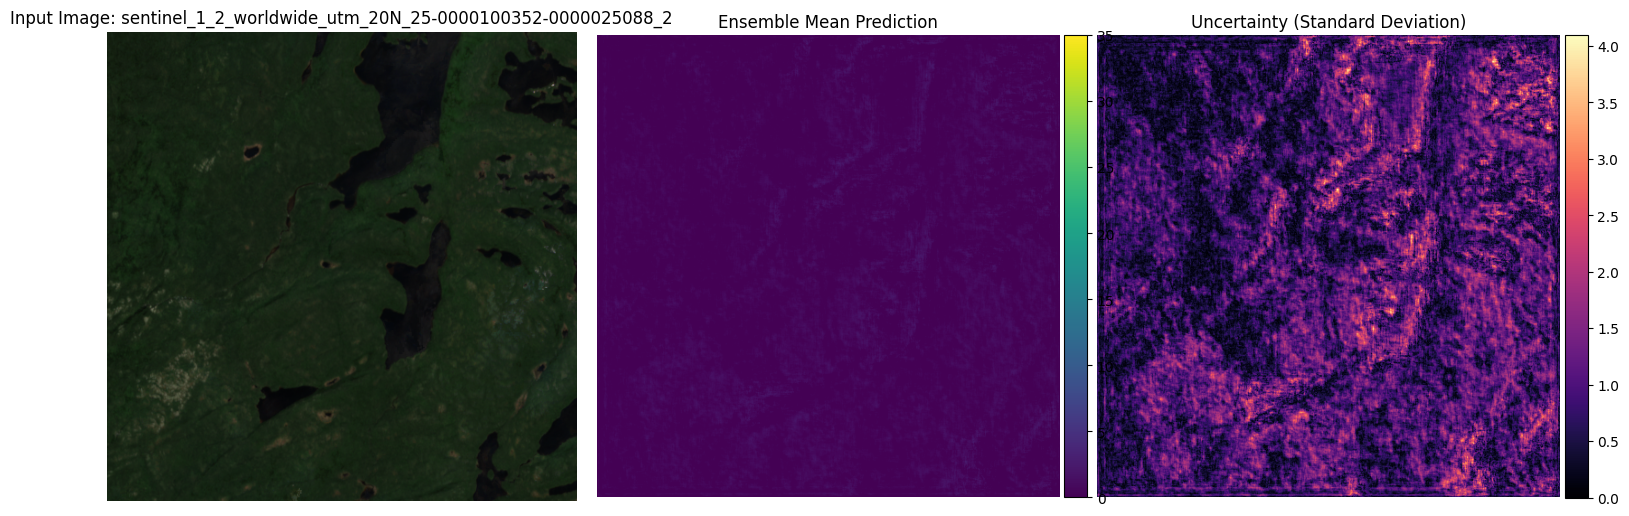

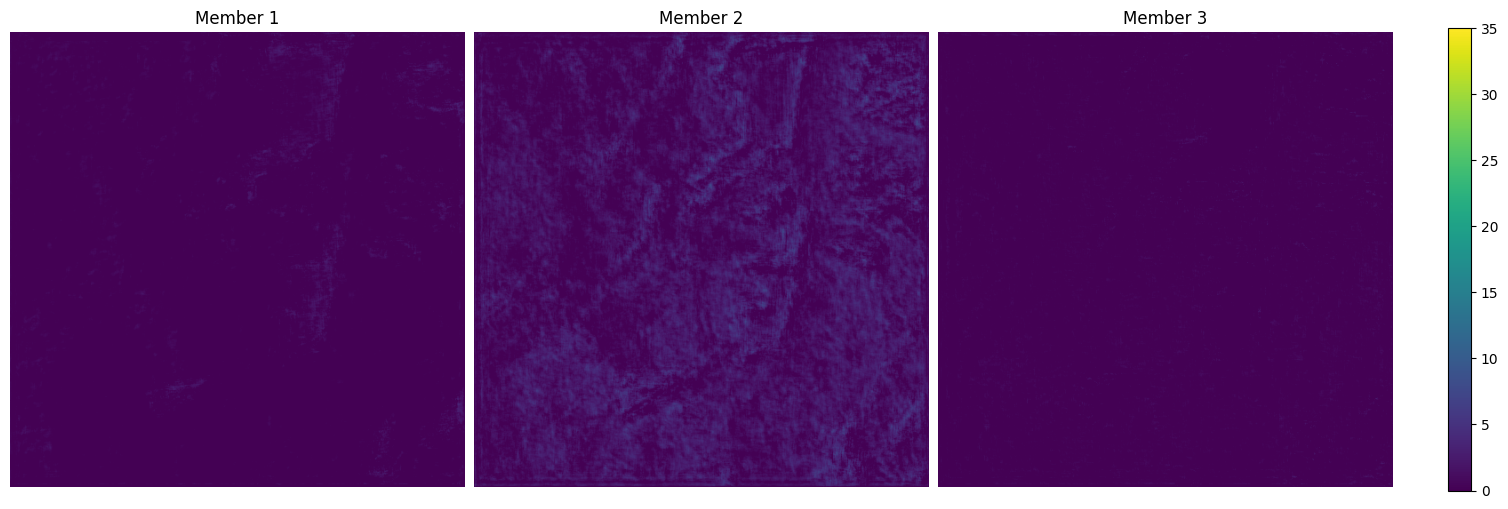

In [9]:
# Run the interactive visualization
PREDICTIONS_FILE = "prediction_outputs/predictions_ensemble.json"
run_visualization_interactive(PREDICTIONS_FILE)

In [50]:
def visualize_prediction(entry, rgb_channels=[6, 5, 4]):
    """
    Visualizes the input image, ensemble predictions, uncertainty, and individual model outputs.
    """
    file_name = entry["file_name"]
    x_input = torch.tensor(entry["input_image"])  # Convert input image back to tensor
    ensemble_outputs = entry["outputs"]
    
    # Extract main ensemble predictions
    mean_prediction = torch.tensor(ensemble_outputs["mean"])
    std_dev = torch.tensor(ensemble_outputs["std_dev"]) if "std_dev" in ensemble_outputs else None
    lower_bound = torch.tensor(ensemble_outputs.get("lower_bound", None))
    upper_bound = torch.tensor(ensemble_outputs.get("upper_bound", None))
    
    # Extract individual ensemble members if available
    #ensemble_members = ensemble_outputs.get("ensemble_members", [])
    ensemble_members = ensemble_outputs.get("individual_predictions", [])

    
    # Normalize input for visualization
    #inputs_min, inputs_max = np.percentile(x_input.numpy(), (2, 98))
    #x_input_normalized = (x_input.numpy() - inputs_min) / (inputs_max - inputs_min + 1e-6)
    #x_input_normalized = np.clip(x_input_normalized, 0, 1)

    x_input_normalized = np.clip(x_input.numpy() / 3000, 0, 1)
    
    # Ensure dimensions are correct for visualization
    if mean_prediction.dim() == 3 and mean_prediction.shape[0] == 1:
        mean_prediction = mean_prediction.squeeze(0)
    if std_dev is not None and std_dev.dim() == 3:
        std_dev = std_dev.squeeze(0)
    
    clear_output(wait=True)
    
    # Plot input image
    plt.figure(figsize=(6, 6))
    plt.imshow(x_input_normalized[rgb_channels, :, :].transpose(1, 2, 0))
    plt.title(f"Input Image: {file_name}")
    plt.axis("off")
    plt.show()
    
    # Determine the color scale for all predictions
    #vmin, vmax = mean_prediction.min().item(), mean_prediction.max().item()
    vmin, vmax = 0, 35
    
    # 🔹 **Mean Prediction**
    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(mean_prediction, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("Ensemble Mean Prediction")
    ax.axis("off")

    # ✅ Adjust Colorbar Size
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    fig.colorbar(im, cax=cax, orientation="vertical", fraction=0.04)
    
    plt.show()

    # 🔹 **Uncertainty Heatmap**
    if std_dev is not None:
        fig, ax = plt.subplots(figsize=(6, 6))
        im = ax.imshow(std_dev, cmap="magma", vmin=0, vmax=std_dev.max())
        ax.set_title("Uncertainty (Standard Deviation)")
        ax.axis("off")

        # ✅ Adjust Colorbar Size
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        fig.colorbar(im, cax=cax, orientation="vertical", fraction=0.04)
        
        plt.show()

    # 🔹 Plot all ensemble members as subplots with a single colorbar
    if ensemble_members:
        num_members = len(ensemble_members)
        fig, axs = plt.subplots(1, num_members, figsize=(5 * num_members, 5), constrained_layout=True)
        
        if num_members == 1:
            axs = [axs]  # Ensure axs is iterable if there's only one member

        for i, member_pred in enumerate(ensemble_members):
            im = axs[i].imshow(torch.tensor(member_pred).squeeze(), cmap="viridis", vmin=vmin, vmax=vmax)
            axs[i].set_title(f"Ensemble Member {i+1} Prediction")
            axs[i].axis("off")

        # Add a single colorbar behind the last subplot
        fig.colorbar(im, ax=axs, orientation="vertical", fraction=0.02, pad=0.04)

        plt.show()

In [40]:
def run_visualization(predictions_file):
    """
    Iterates through predictions and visualizes each one step-by-step.
    """
    prediction_stream = stream_predictions(predictions_file)
    print("Press ENTER to show next image or type 'exit' to stop.")
    
    for entry in prediction_stream:
        visualize_prediction(entry)
        user_input = input("Press ENTER for next or type 'exit' to stop: ")
        if user_input.lower() == "exit":
            break

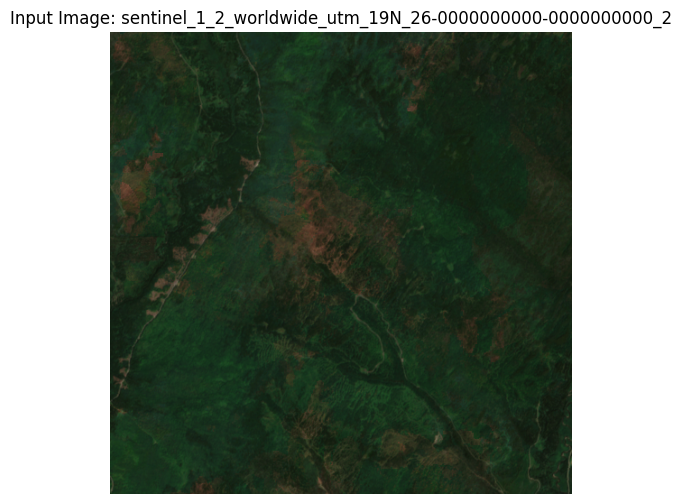

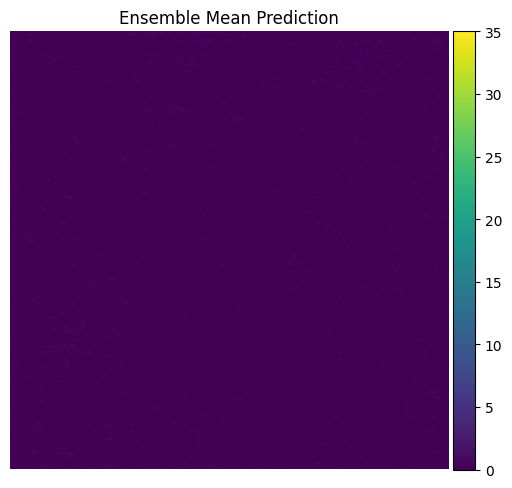

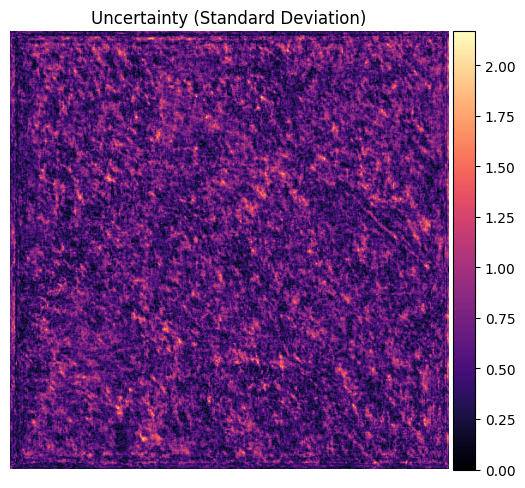

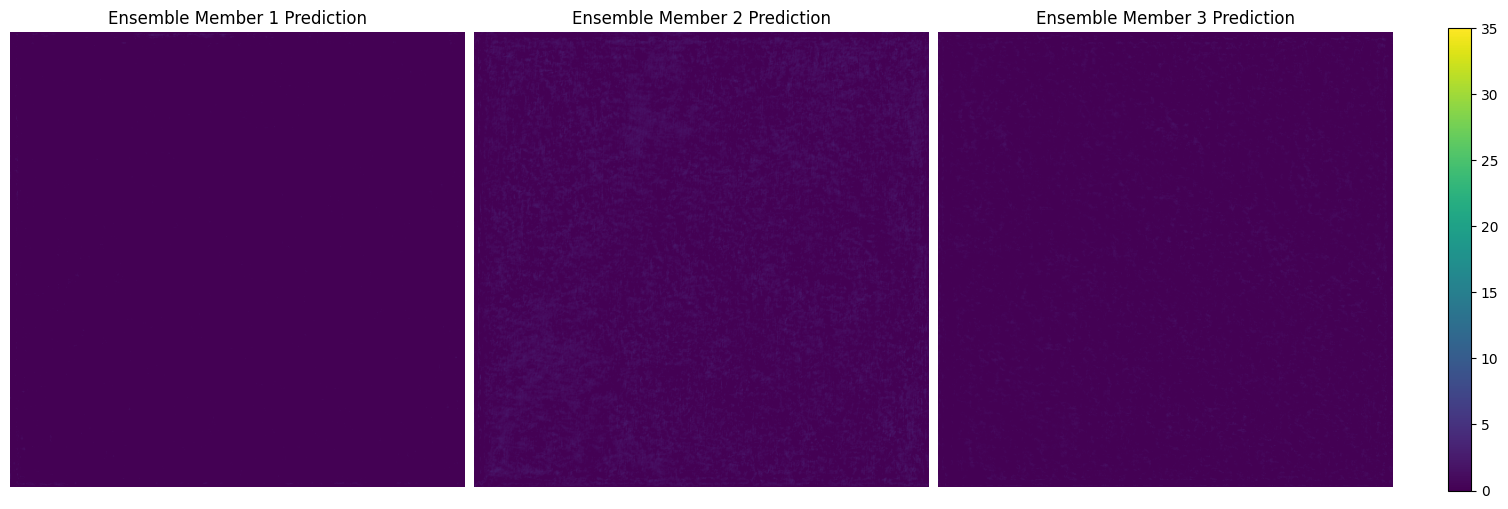

Press ENTER for next or type 'exit' to stop:  


In [38]:
# Set the path to the predictions JSON file
PREDICTIONS_FILE = "prediction_outputs/predictions_ensemble.json"  # Adjust for your model variant
run_visualization(PREDICTIONS_FILE)

In [18]:
def old_single_plots_visualize_prediction(entry):
    """
    Visualizes the input image, ensemble predictions, uncertainty, and individual model outputs.
    """
    rgb_channels = [6, 5, 4]
    file_name = entry["file_name"]
    x_input = torch.tensor(entry["input_image"])  # Convert input image back to tensor
    ensemble_outputs = entry["outputs"]
    
    # Extract main ensemble predictions
    mean_prediction = torch.tensor(ensemble_outputs["mean"])
    std_dev = torch.tensor(ensemble_outputs["std_dev"]) if "std_dev" in ensemble_outputs else None
    lower_bound = torch.tensor(ensemble_outputs.get("lower_bound", None))
    upper_bound = torch.tensor(ensemble_outputs.get("upper_bound", None))
    
    # Extract individual ensemble members if available
    ensemble_members = ensemble_outputs.get("ensemble_members", [])
    
    # Ensure dimensions are correct for visualization
    if mean_prediction.dim() == 2:
        mean_prediction = mean_prediction.unsqueeze(0)  # Add missing channel dim
    if std_dev is not None and std_dev.dim() == 2:
        std_dev = std_dev.unsqueeze(0)
    
    # Clear previous output
    clear_output(wait=True)
    
    subplot_count = 2  # Start with 2 subplots (Input + Mean Prediction)
    
    # Add uncertainty plot if std_dev is available
    if std_dev is not None:
        subplot_count += 1
    
    # Add space for each ensemble member
    subplot_count += len(ensemble_members)
    
    # Now use subplot_count dynamically
    plt.figure(figsize=(15, 10))

        inputs = x_input[rgb_channels,:,:].cpu().detach().numpy()
        outputs = outputs.cpu().detach().numpy()

        print(f"DEBUG: input shape: {inputs.shape}, output shape: {outputs.shape}")

        # Normalize inputs for visualization
        inputs_normalized = np.clip(inputs / 3000, 0, 1)


        # Plot the RGB input image
        #axs[0].imshow(inputs_normalized[0, rgb_channels, :, :].transpose(1, 2, 0))  # Convert CHW to HWC
        axs[0].imshow(inputs_normalized[rgb_channels, :, :].transpose(1, 2, 0))  # Convert CHW to HWC
        axs[0].set_title("RGB Input Image")
        axs[0].axis("off")
    
    plt.subplot(subplot_count, 1, 1)
    plt.imshow(x_input[rgb_channels,:,:].permut(2,0,1)  # Input image
    plt.title(f"Input Image: {file_name} (Channels {rgb_channels})")
    plt.axis("off")
    
    plt.subplot(subplot_count, 1, 2)
    plt.imshow(mean_prediction.squeeze(), cmap="viridis")  # Mean prediction
    plt.title("Ensemble Mean Prediction")
    plt.colorbar()
    
    # Only add the std_dev plot if it exists
    if std_dev is not None:
        plt.subplot(subplot_count, 1, 3)
        plt.imshow(std_dev.squeeze(), cmap="magma")
        plt.title("Uncertainty (Standard Deviation)")
        plt.colorbar()
    
    # Plot each ensemble member
    for i, member_pred in enumerate(ensemble_members):
        plt.subplot(subplot_count, 1, 4 + i)
        plt.imshow(torch.tensor(member_pred).squeeze(), cmap="cividis")
        plt.title(f"Ensemble Member {i+1} Prediction")
        plt.colorbar()
    
    plt.show()